# 03 — Ego4D Dataset Statistics (DataLoader-Only)

This notebook computes comprehensive dataset statistics for **Ego4D** using **exclusively the unified PyTorch `DataLoader`** (`EgoClipDataset.from_config` + `torch.utils.data.DataLoader`). No raw dataset files, index JSONLs, or adapters are accessed directly.

### What Ego4D provides through `DataLoader`
- **Narrations & FHO Action Windows (`sampling="actions"`):** large-scale egocentric daily-life narrations plus Forecasting Hands and Objects (FHO) interaction actions.
- **FHO Hand & Object 2D Bounding Boxes (`hand_bbox_2d`, `hand_bbox_valid`, `obj_bbox_2d`, `obj_valid`):** sparse human-annotated 2D boxes on critical FHO frames.
- **FHO Contact-Onset & Point-of-No-Return Keyframes (`keyframe`, `keyframe_valid`):** real human contact timing (`keyframe[:, 0]` = contact onset, `keyframe[:, 1]` = PNR).
- **Audio, Device-Frame IMU & Eye Gaze (`audio`, `imu`, `gaze_2d`):** optional sensors available on subsets of videos (`imu_in_camera_frame == False`, `gravity_cam == 0`).

### Multi-Pass DataLoader Strategy
Because Ego4D videos have heterogeneous native resolutions (`1440×1080`, `1920×1080`, `2560×1920`, etc.), we apply the unified `transforms={resize: 256, center_crop: [256, 256]}` even in annotation-only passes (`transforms.py` maps 2D boxes and gaze analytically without decoding video!), placing all spatial statistics in the exact `256×256` training grid.
1. **Pass 1 — Broad Action-Centred Scan across all Ego4D videos** (`modalities=["imu", "gaze", "keyframes"]`).
2. **Pass 2 — FHO-Focused `DataLoader`** (`require_modalities=["hand_box"]`, `modalities=["keyframes"]`) for detailed 2D hand/object box geometry, sparsity, hand–object proximity/IoU, and contact-to-PNR timing.
3. **Pass 3 — Targeted Sensor `DataLoader`s** (`require_modalities=["imu"]` and `require_modalities=["gaze"]`) to inspect device-frame IMU and eye-gaze distributions cleanly.
4. **Pass 4 — Dense Multimodal `DataLoader`** (`modalities=["rgb", "audio", "keyframes"]`, `require_modalities=["hand_box"]`) for RGB/audio distributions and visual FHO box + keyframe sanity checks.

In [1]:
import re
import time
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Subset

from robot.data.torch_dataset import EgoClipDataset

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# --- Notebook Configuration ---
SEED = 42
PASS1_MAX_CLIPS = 6000   # Broad stratified-style random sample across all ~461k action clips
PASS2_MAX_CLIPS = 5000   # FHO hand/object box + keyframe clips
PASS3_IMU_CLIPS = 1500   # Device-frame IMU clips
PASS3_GAZE_CLIPS = 400   # Gaze clips (1 video)
PASS4_MAX_CLIPS = 64     # Dense RGB + Audio + FHO clips
BATCH_SIZE_ANN = 128
BATCH_SIZE_DENSE = 8
NUM_WORKERS = 8
GRID = 256.0             # Unified training crop size

STOPWORDS = {
    "c", "the", "a", "an", "on", "in", "of", "to", "with", "from", "at", "by", "his", "her",
    "into", "onto", "up", "down", "out", "off", "and", "over", "it", "o", "x", "p", "hand",
    "hands", "right", "left", "both", "person", "man", "woman", "unsure",
}

def make_loader(cfg: dict, max_clips: int | None, batch_size: int, seed: int = SEED) -> tuple[DataLoader, int]:
    ds = EgoClipDataset.from_config(cfg)
    total = len(ds)
    if max_clips is not None and total > max_clips:
        rng = np.random.default_rng(seed)
        idx = np.sort(rng.choice(total, size=max_clips, replace=False)).tolist()
        ds_view = Subset(ds, idx)
    else:
        ds_view = ds
    dl = DataLoader(ds_view, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
    return dl, total

def box_iou(a: np.ndarray, b: np.ndarray) -> float:
    x0, y0 = max(a[0], b[0]), max(a[1], b[1])
    x1, y1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, x1 - x0) * max(0.0, y1 - y0)
    aa = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    ab = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    denom = aa + ab - inter
    return inter / denom if denom > 1e-6 else 0.0

print("Setup complete. PyTorch:", torch.__version__)

Setup complete. PyTorch: 2.14.1+rocm7.2


## 1. Pass 1 — Broad Ego4D Action & Modality Coverage Scan via `DataLoader`

Pass 1 DataLoader ready in 10.78s | total action clips: 461,161 | iterating: 6,000


Pass 1 completed in 17.28s | 6,000 clips across 705 unique videos


,Broad Ego4D Metric (Pass 1),Value
0,Total action clips in DataLoader,"461,161"
1,Clips sampled in Pass 1,"6,000"
2,Unique video UIDs hit in Pass 1,705
3,Clips with non-empty action/narration,100.0% (median 6 words)
4,Clips with FHO hand 2D box,37.3%
5,Clips with FHO object 2D box,36.7%
6,Clips with keyframe_valid (FHO),"48.7% (contact: 19.0%, PNR: 32.5%)"
7,Clips with valid IMU / camera-frame IMU,5.78% / 0.00%
8,Clips with valid Gaze,0.950%
9,3D GT flags (K / hand_3d / obj_pose / cam),0 / 0 / 0 / 0


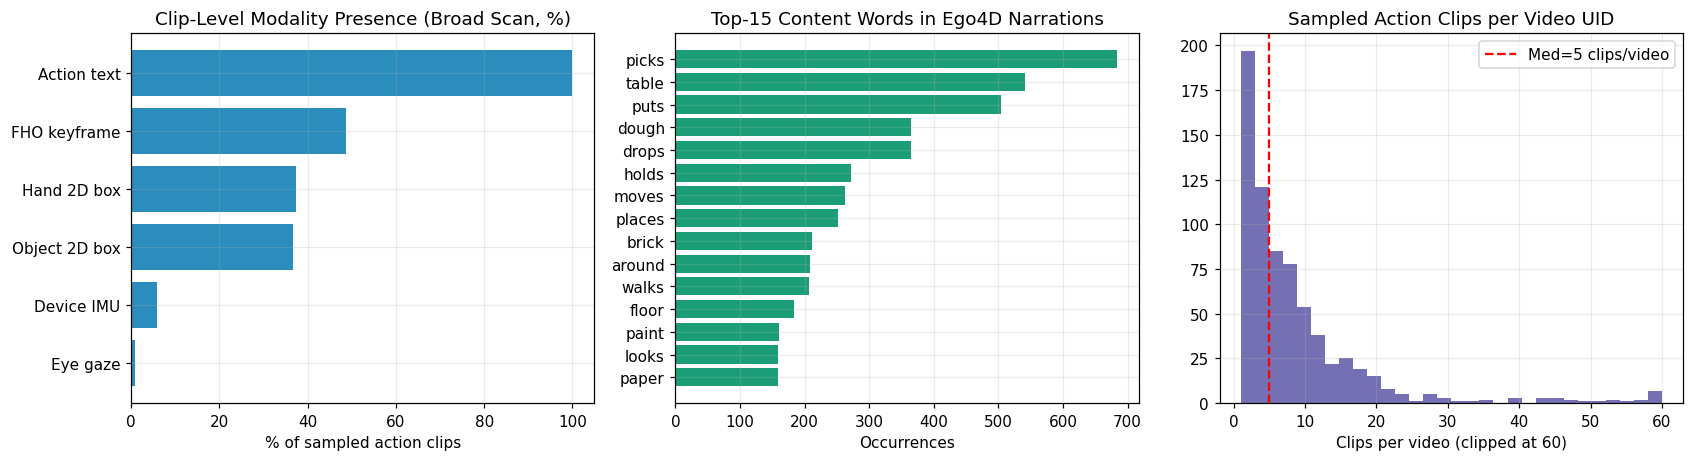

In [2]:
cfg_pass1 = {
    "clip_len": 16,
    "fps": 15,
    "max_objects": 6,
    "modalities": ["imu", "gaze", "keyframes"],
    "transforms": {"resize": 256, "center_crop": [256, 256]},
    "sources": [
        {
            "dataset": "ego4d",
            "sampling": "actions",
        }
    ],
}

t0 = time.time()
dl_p1, total_windows_p1 = make_loader(cfg_pass1, PASS1_MAX_CLIPS, BATCH_SIZE_ANN)
print(f"Pass 1 DataLoader ready in {time.time() - t0:.2f}s | total action clips: {total_windows_p1:,} | iterating: {len(dl_p1.dataset):,}")

p1_rows = []
word_counter = Counter()
narration_counter = Counter()
gt_flags = Counter()

t_scan = time.time()
for batch in dl_p1:
    B, T = batch["timestamps"].shape
    ts = batch["timestamps"].numpy()
    hbv = batch["hand_bbox_valid"].numpy()   # (B, 2, T)
    ov = batch["obj_valid"].numpy()          # (B, O, T)
    kfv = batch["keyframe_valid"].numpy()    # (B,)
    kf = batch["keyframe"].numpy()           # (B, 2, T) [contact, PNR]
    imuv = batch["imu_valid"].numpy()        # (B, T)
    imucam = batch["imu_in_camera_frame"].numpy()
    gzv = batch["gaze_valid"].numpy()        # (B, T)

    gt_flags["K_valid"] += int(batch["K_valid"].sum())
    gt_flags["hand_3d"] += int(batch["hand_joints_3d_valid"].any(dim=(1, 2)).sum())
    gt_flags["obj_pose"] += int(batch["obj_pose_valid"].any(dim=(1, 2)).sum())
    gt_flags["cam_pose"] += int(batch["cam_valid"].any(dim=1).sum())

    for b in range(B):
        act = (batch["action"][b] or "").strip()
        clean_act = re.sub(r"^#[A-Za-z]+\s+[A-Za-z]\s+", "", act).strip().lower()
        if clean_act:
            narration_counter[clean_act] += 1
        toks = [w for w in re.split(r"[^a-z]+", clean_act) if len(w) >= 2]
        for w in toks:
            if w not in STOPWORDS:
                word_counter[w] += 1

        p1_rows.append({
            "sequence_id": batch["sequence_id"][b],
            "end_s": float(ts[b, -1]),
            "n_words": len(toks),
            "has_action": bool(act),
            "has_hand_box": bool(hbv[b].any()),
            "has_obj_box": bool(ov[b].any()),
            "keyframe_valid": bool(kfv[b]),
            "has_contact_kf": bool(kfv[b] and kf[b, 0].any()),
            "has_pnr_kf": bool(kfv[b] and kf[b, 1].any()),
            "has_imu": bool(imuv[b].any()),
            "imu_in_cam": bool(imucam[b]),
            "has_gaze": bool(gzv[b].any()),
        })

df1 = pd.DataFrame(p1_rows)
print(f"Pass 1 completed in {time.time() - t_scan:.2f}s | {len(df1):,} clips across {df1['sequence_id'].nunique():,} unique videos")

summary1 = pd.DataFrame([
    ("Total action clips in DataLoader", f"{total_windows_p1:,}"),
    ("Clips sampled in Pass 1", f"{len(df1):,}"),
    ("Unique video UIDs hit in Pass 1", f"{df1['sequence_id'].nunique():,}"),
    ("Clips with non-empty action/narration", f"{df1['has_action'].mean()*100:.1f}% (median {df1['n_words'].median():.0f} words)"),
    ("Clips with FHO hand 2D box", f"{df1['has_hand_box'].mean()*100:.1f}%"),
    ("Clips with FHO object 2D box", f"{df1['has_obj_box'].mean()*100:.1f}%"),
    ("Clips with keyframe_valid (FHO)", f"{df1['keyframe_valid'].mean()*100:.1f}% (contact: {df1['has_contact_kf'].mean()*100:.1f}%, PNR: {df1['has_pnr_kf'].mean()*100:.1f}%)"),
    ("Clips with valid IMU / camera-frame IMU", f"{df1['has_imu'].mean()*100:.2f}% / {df1['imu_in_cam'].mean()*100:.2f}%"),
    ("Clips with valid Gaze", f"{df1['has_gaze'].mean()*100:.3f}%"),
    ("3D GT flags (K / hand_3d / obj_pose / cam)", f"{gt_flags['K_valid']} / {gt_flags['hand_3d']} / {gt_flags['obj_pose']} / {gt_flags['cam_pose']}"),
], columns=["Broad Ego4D Metric (Pass 1)", "Value"])
display(summary1)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))

# Modality presence rates
mod_rates = pd.Series({
    "Action text": df1["has_action"].mean() * 100,
    "FHO keyframe": df1["keyframe_valid"].mean() * 100,
    "Hand 2D box": df1["has_hand_box"].mean() * 100,
    "Object 2D box": df1["has_obj_box"].mean() * 100,
    "Device IMU": df1["has_imu"].mean() * 100,
    "Eye gaze": df1["has_gaze"].mean() * 100,
})
axes[0].barh(mod_rates.index[::-1], mod_rates.values[::-1], color="#2b8cbe")
axes[0].set_title("Clip-Level Modality Presence (Broad Scan, %)")
axes[0].set_xlabel("% of sampled action clips")

# Top content words in narrations
tw = pd.DataFrame(word_counter.most_common(15), columns=["word", "count"]).iloc[::-1]
axes[1].barh(tw["word"], tw["count"], color="#1b9e77")
axes[1].set_title("Top-15 Content Words in Ego4D Narrations")
axes[1].set_xlabel("Occurrences")

# Sampled clips per video UID distribution
vid_cnts = df1["sequence_id"].value_counts()
axes[2].hist(np.clip(vid_cnts.values, 0, 60), bins=30, color="#7570b3")
axes[2].axvline(vid_cnts.median(), color="red", ls="--", label=f"Med={vid_cnts.median():.0f} clips/video")
axes[2].set_title("Sampled Action Clips per Video UID")
axes[2].set_xlabel("Clips per video (clipped at 60)")
axes[2].legend()

plt.tight_layout()
plt.show()

## 2. Pass 2 — FHO Hand/Object 2D Boxes & Contact/PNR Keyframes (`require_modalities=["hand_box"]`)

We configure `EgoClipDataset.from_config` with `require_modalities: ["hand_box"]` to analyze the FHO subset in depth: box sparsity per clip, left/right/bimanual presence, spatial heatmaps in the `256×256` training crop, box size & aspect ratio, hand–object 2D IoU, and **Contact-Onset → PNR latency**.

Pass 2 FHO DataLoader ready in 9.01s | total FHO-video clips: 357,201 | iterating: 5,000


Pass 2 completed in 4.83s


,Ego4D FHO Metric (Pass 2),Value
0,Clips with >=1 hand box / >=1 object box,47.1% / 45.9%
1,Mean annotated frames per box-bearing clip (ha...,2.30 / 2.22 (of 16)
2,Hand presence on annotated frames (L / R / Both),397 / 642 / 4377
3,Hand box centers inside 256×256 center crop,93.7% (objects: 96.5%)
4,Median box area fraction of 256×256 (hand / obj),3.22% / 4.57%
5,Hand–object 2D IoU > 0 rate / median IoU,63.0% / 0.034
6,FHO keyframe_valid clips,3031/5000 (60.6%)
7,Clips with Contact / PNR / Both keyframes,1214 / 2051 / 1079
8,Contact-onset → PNR latency [p10 / med / p90],0.00 / 0.13 / 0.33 s
9,Keyframes co-occurring with hand/obj boxes,52.2%


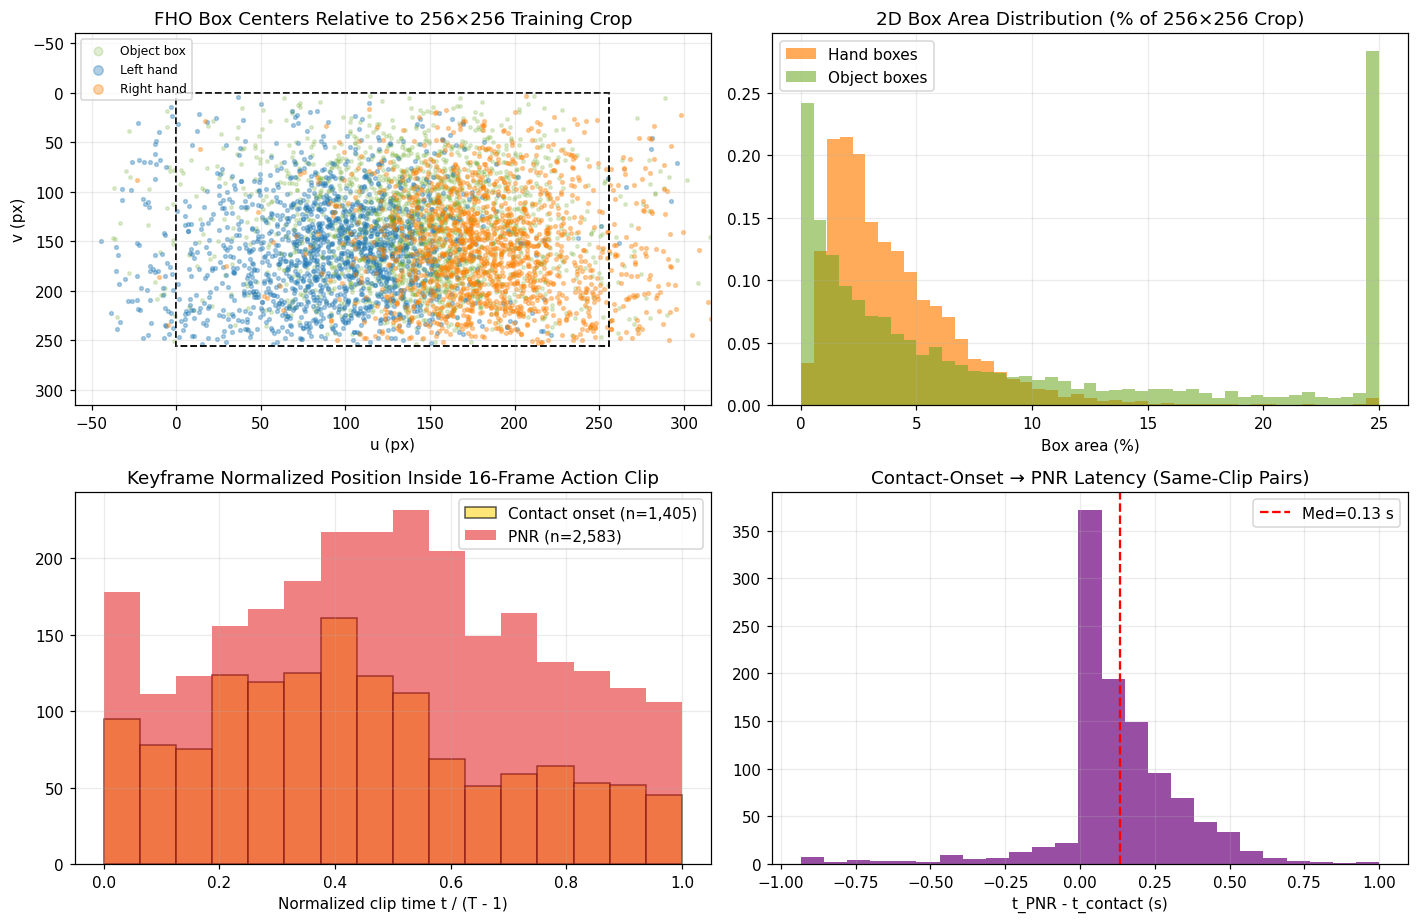

In [3]:
cfg_pass2 = {
    "clip_len": 16,
    "fps": 15,
    "max_objects": 6,
    "modalities": ["keyframes"],
    "transforms": {"resize": 256, "center_crop": [256, 256]},
    "sources": [
        {
            "dataset": "ego4d",
            "require_modalities": ["hand_box"],
            "sampling": "actions",
        }
    ],
}

t0 = time.time()
dl_p2, total_fho_clips = make_loader(cfg_pass2, PASS2_MAX_CLIPS, BATCH_SIZE_ANN, seed=SEED + 2)
print(f"Pass 2 FHO DataLoader ready in {time.time() - t0:.2f}s | total FHO-video clips: {total_fho_clips:,} | iterating: {len(dl_p2.dataset):,}")

hand_centers = {"left": [], "right": []}
hand_areas = []
hand_in_crop = []
obj_centers = []
obj_areas = []
obj_in_crop = []
ho_ious = []
ho_dists = []

frames_with_hbox_per_clip = []
frames_with_obox_per_clip = []
objs_per_annotated_frame = []
hand_side_counts = Counter()  # left_only, right_only, both

kf_contact_pos = []
kf_pnr_pos = []
contact_to_pnr_s = []
kf_clips_valid = 0
kf_clips_contact = 0
kf_clips_pnr = 0
kf_clips_both = 0
kf_with_box_overlap = [0, 0]  # [kf frames that also have a hand/obj box, total kf frames]

t_scan = time.time()
for batch in dl_p2:
    B, T = batch["timestamps"].shape
    ts = batch["timestamps"].numpy()
    hb = batch["hand_bbox_2d"].numpy()       # (B, 2, T, 4) xyxy in 256x256 crop
    hbv = batch["hand_bbox_valid"].numpy()   # (B, 2, T)
    ob = batch["obj_bbox_2d"].numpy()        # (B, O, T, 4)
    ov = batch["obj_valid"].numpy()          # (B, O, T)
    kf = batch["keyframe"].numpy()           # (B, 2, T)
    kfv = batch["keyframe_valid"].numpy()    # (B,)

    for b in range(B):
        any_h_t = hbv[b].any(axis=0)         # (T,)
        any_o_t = ov[b].any(axis=0)          # (T,)
        frames_with_hbox_per_clip.append(int(any_h_t.sum()))
        frames_with_obox_per_clip.append(int(any_o_t.sum()))

        for t in np.flatnonzero(any_h_t):
            l_ok, r_ok = bool(hbv[b, 0, t]), bool(hbv[b, 1, t])
            if l_ok and r_ok:
                hand_side_counts["Both hands"] += 1
            elif l_ok:
                hand_side_counts["Left only"] += 1
            else:
                hand_side_counts["Right only"] += 1

            for s_i, side in enumerate(("left", "right")):
                if hbv[b, s_i, t]:
                    x0, y0, x1, y1 = hb[b, s_i, t]
                    cx, cy = 0.5 * (x0 + x1), 0.5 * (y0 + y1)
                    bw, bh = max(0.0, x1 - x0), max(0.0, y1 - y0)
                    hand_centers[side].append((cx, cy))
                    hand_areas.append((bw * bh) / (GRID * GRID))
                    hand_in_crop.append((0 <= cx <= GRID) and (0 <= cy <= GRID))

        for t in np.flatnonzero(any_o_t):
            active_o = np.flatnonzero(ov[b, :, t])
            objs_per_annotated_frame.append(len(active_o))
            for o in active_o:
                x0, y0, x1, y1 = ob[b, o, t]
                cx, cy = 0.5 * (x0 + x1), 0.5 * (y0 + y1)
                bw, bh = max(0.0, x1 - x0), max(0.0, y1 - y0)
                obj_centers.append((cx, cy))
                obj_areas.append((bw * bh) / (GRID * GRID))
                obj_in_crop.append((0 <= cx <= GRID) and (0 <= cy <= GRID))

                # Hand-object 2D IoU & normalized center distance on co-annotated frames
                for s_i in range(2):
                    if hbv[b, s_i, t]:
                        hbox = hb[b, s_i, t]
                        ho_ious.append(box_iou(hbox, ob[b, o, t]))
                        hcx, hcy = 0.5 * (hbox[0] + hbox[2]), 0.5 * (hbox[1] + hbox[3])
                        ho_dists.append(np.hypot(hcx - cx, hcy - cy) / GRID)

        if kfv[b]:
            kf_clips_valid += 1
            c_idx = np.flatnonzero(kf[b, 0])
            p_idx = np.flatnonzero(kf[b, 1])
            if len(c_idx):
                kf_clips_contact += 1
                kf_contact_pos.extend((c_idx / max(T - 1, 1)).tolist())
            if len(p_idx):
                kf_clips_pnr += 1
                kf_pnr_pos.extend((p_idx / max(T - 1, 1)).tolist())
            if len(c_idx) and len(p_idx):
                kf_clips_both += 1
                # Nearest PNR after or around contact onset
                diffs = ts[b, p_idx][:, None] - ts[b, c_idx][None, :]
                best = diffs.ravel()[np.argmin(np.abs(diffs.ravel()))]
                contact_to_pnr_s.append(float(best))
            kf_any = kf[b].any(axis=0)
            kf_with_box_overlap[1] += int(kf_any.sum())
            kf_with_box_overlap[0] += int((kf_any & (any_h_t | any_o_t)).sum())

print(f"Pass 2 completed in {time.time() - t_scan:.2f}s")

fho_stats = pd.DataFrame([
    ("Clips with >=1 hand box / >=1 object box", f"{100*np.mean(np.array(frames_with_hbox_per_clip)>0):.1f}% / {100*np.mean(np.array(frames_with_obox_per_clip)>0):.1f}%"),
    ("Mean annotated frames per box-bearing clip (hand / obj)", f"{np.mean([x for x in frames_with_hbox_per_clip if x>0]):.2f} / {np.mean([x for x in frames_with_obox_per_clip if x>0]):.2f} (of 16)"),
    ("Hand presence on annotated frames (L / R / Both)", f"{hand_side_counts['Left only']} / {hand_side_counts['Right only']} / {hand_side_counts['Both hands']}"),
    ("Hand box centers inside 256×256 center crop", f"{100*np.mean(hand_in_crop):.1f}% (objects: {100*np.mean(obj_in_crop):.1f}%)"),
    ("Median box area fraction of 256×256 (hand / obj)", f"{np.median(hand_areas)*100:.2f}% / {np.median(obj_areas)*100:.2f}%"),
    ("Hand–object 2D IoU > 0 rate / median IoU", f"{100*np.mean(np.array(ho_ious)>0):.1f}% / {np.median(ho_ious):.3f}"),
    ("FHO keyframe_valid clips", f"{kf_clips_valid}/{len(dl_p2.dataset)} ({100*kf_clips_valid/len(dl_p2.dataset):.1f}%)"),
    ("Clips with Contact / PNR / Both keyframes", f"{kf_clips_contact} / {kf_clips_pnr} / {kf_clips_both}"),
    ("Contact-onset → PNR latency [p10 / med / p90]", f"{np.percentile(contact_to_pnr_s, 10):.2f} / {np.median(contact_to_pnr_s):.2f} / {np.percentile(contact_to_pnr_s, 90):.2f} s" if contact_to_pnr_s else "N/A"),
    ("Keyframes co-occurring with hand/obj boxes", f"{100*kf_with_box_overlap[0]/max(kf_with_box_overlap[1],1):.1f}%"),
], columns=["Ego4D FHO Metric (Pass 2)", "Value"])
display(fho_stats)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# 1. Spatial box centers in 256x256 training crop
hl = np.array(hand_centers["left"]) if hand_centers["left"] else np.zeros((0, 2))
hr = np.array(hand_centers["right"]) if hand_centers["right"] else np.zeros((0, 2))
oc = np.array(obj_centers) if obj_centers else np.zeros((0, 2))
rng = np.random.default_rng(0)
if len(oc):
    s = oc[rng.choice(len(oc), min(2000, len(oc)), replace=False)]
    axes[0, 0].scatter(s[:, 0], s[:, 1], s=5, alpha=0.2, color="#66a61e", label="Object box")
if len(hl):
    s = hl[rng.choice(len(hl), min(1500, len(hl)), replace=False)]
    axes[0, 0].scatter(s[:, 0], s[:, 1], s=6, alpha=0.35, color="#1f78b4", label="Left hand")
if len(hr):
    s = hr[rng.choice(len(hr), min(1500, len(hr)), replace=False)]
    axes[0, 0].scatter(s[:, 0], s[:, 1], s=6, alpha=0.35, color="#ff7f00", label="Right hand")
axes[0, 0].add_patch(plt.Rectangle((0, 0), 256, 256, fill=False, edgecolor="black", ls="--", lw=1.2))
axes[0, 0].set_xlim(-60, 316)
axes[0, 0].set_ylim(316, -60)
axes[0, 0].set_title("FHO Box Centers Relative to 256×256 Training Crop")
axes[0, 0].set_xlabel("u (px)")
axes[0, 0].set_ylabel("v (px)")
axes[0, 0].legend(markerscale=2.5, fontsize=8)

# 2. Hand vs Object box area
axes[0, 1].hist(np.clip(np.array(hand_areas) * 100, 0, 25), bins=45, alpha=0.65, color="#ff7f00", label="Hand boxes", density=True)
axes[0, 1].hist(np.clip(np.array(obj_areas) * 100, 0, 25), bins=45, alpha=0.55, color="#66a61e", label="Object boxes", density=True)
axes[0, 1].set_title("2D Box Area Distribution (% of 256×256 Crop)")
axes[0, 1].set_xlabel("Box area (%)")
axes[0, 1].legend()

# 3. Temporal position of Contact vs PNR inside action clip
axes[1, 0].hist(kf_contact_pos, bins=16, range=(0, 1), alpha=0.65, color="#ffd92f", edgecolor="black", label=f"Contact onset (n={len(kf_contact_pos):,})")
axes[1, 0].hist(kf_pnr_pos, bins=16, range=(0, 1), alpha=0.55, color="#e41a1c", label=f"PNR (n={len(kf_pnr_pos):,})")
axes[1, 0].set_title("Keyframe Normalized Position Inside 16-Frame Action Clip")
axes[1, 0].set_xlabel("Normalized clip time t / (T - 1)")
axes[1, 0].legend()

# 4. Contact -> PNR latency
if contact_to_pnr_s:
    axes[1, 1].hist(contact_to_pnr_s, bins=25, color="#984ea3")
    axes[1, 1].axvline(np.median(contact_to_pnr_s), color="red", ls="--", label=f"Med={np.median(contact_to_pnr_s):.2f} s")
    axes[1, 1].set_title("Contact-Onset → PNR Latency (Same-Clip Pairs)")
    axes[1, 1].set_xlabel("t_PNR - t_contact (s)")
    axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 3. Pass 3 — Targeted Device-Frame IMU & Eye-Gaze `DataLoader`s

Because IMU (67/831 videos) and eye gaze (1/831 videos) exist only on specific subsets of Ego4D, we query them directly via `require_modalities=["imu"]` and `require_modalities=["gaze"]` in `EgoClipDataset.from_config`.

,Ego4D Sensor Metric (Pass 3),Value
0,IMU clips available / sampled / unique videos,"28,081 / 1,500 / 63"
1,IMU accel ||a|| [p10 / med / p90] m/s²,8.54 / 9.85 / 10.77
2,IMU gyro ||ω|| [med / p90] rad/s,0.288 / 1.090
3,imu_in_camera_frame / nonzero gravity_cam,0 / 0 (expected 0: device frame)
4,Gaze clips available / sampled / unique videos,"2,681 / 400 / 1"
5,Gaze frame validity (conf >= 0.6),"100.0% (6,400 points)"
6,"Gaze median (u, v) in 256×256 crop","(138.1, 178.4) px"


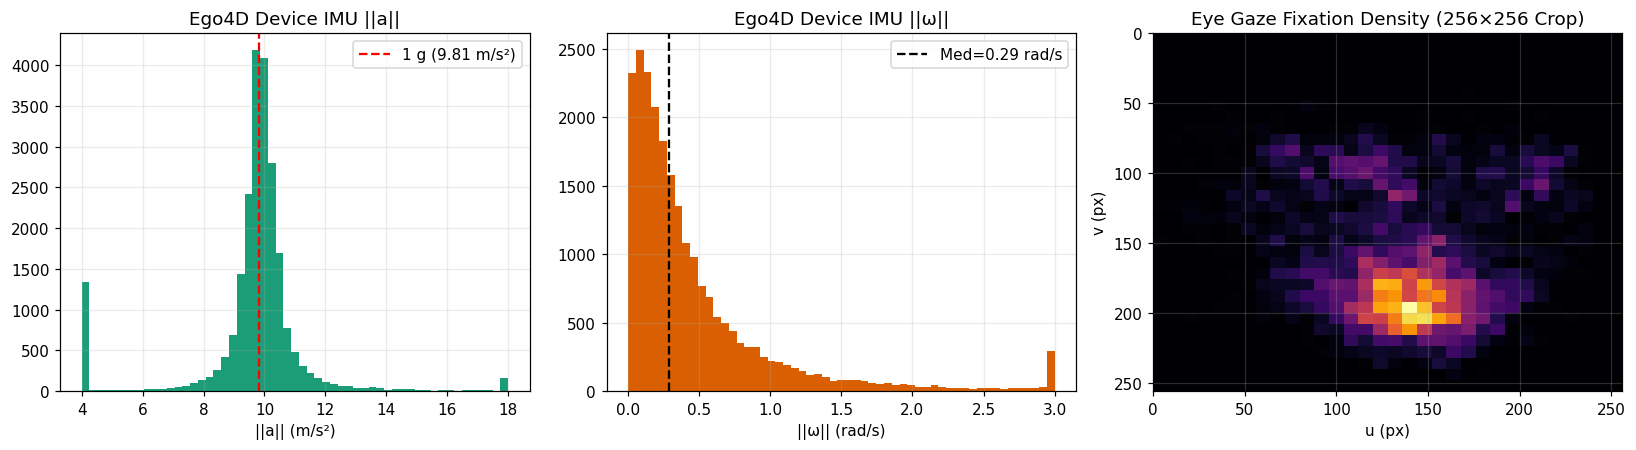

In [4]:
# 3A: Device-frame IMU DataLoader
cfg_imu = {
    "clip_len": 16, "fps": 15, "max_objects": 4,
    "modalities": ["imu"],
    "sources": [{"dataset": "ego4d", "require_modalities": ["imu"], "sampling": "actions"}],
}
dl_imu, total_imu_clips = make_loader(cfg_imu, PASS3_IMU_CLIPS, BATCH_SIZE_ANN, seed=SEED + 3)

imu_acc, imu_gyr = [], []
imu_cam_true = 0
gcam_nonzero = 0
imu_seqs = set()
for batch in dl_imu:
    imu = batch["imu"].numpy()
    iv = batch["imu_valid"].numpy()
    imu_cam_true += int(batch["imu_in_camera_frame"].sum())
    gcam_nonzero += int((np.linalg.norm(batch["gravity_cam"].numpy(), axis=-1) > 1e-6).sum())
    imu_seqs.update(batch["sequence_id"])
    if iv.any():
        imu_acc.append(imu[iv, :3])
        imu_gyr.append(imu[iv, 3:])

imu_acc = np.concatenate(imu_acc) if imu_acc else np.zeros((0, 3))
imu_gyr = np.concatenate(imu_gyr) if imu_gyr else np.zeros((0, 3))

# 3B: Gaze DataLoader
cfg_gaze = {
    "clip_len": 16, "fps": 15, "max_objects": 4,
    "modalities": ["gaze"],
    "transforms": {"resize": 256, "center_crop": [256, 256]},
    "sources": [{"dataset": "ego4d", "require_modalities": ["gaze"], "sampling": "sliding", "stride_s": 2.0}],
}
dl_gaze, total_gaze_clips = make_loader(cfg_gaze, PASS3_GAZE_CLIPS, BATCH_SIZE_ANN, seed=SEED + 4)

gaze_pts = []
gaze_valid_frames = 0
gaze_total_frames = 0
gaze_seqs = set()
for batch in dl_gaze:
    gz = batch["gaze_2d"].numpy()
    gv = batch["gaze_valid"].numpy()
    gaze_valid_frames += int(gv.sum())
    gaze_total_frames += int(gv.size)
    gaze_seqs.update(batch["sequence_id"])
    if gv.any():
        gaze_pts.append(gz[gv])
gaze_pts = np.concatenate(gaze_pts) if gaze_pts else np.zeros((0, 2))

sensor_df = pd.DataFrame([
    ("IMU clips available / sampled / unique videos", f"{total_imu_clips:,} / {len(dl_imu.dataset):,} / {len(imu_seqs)}"),
    ("IMU accel ||a|| [p10 / med / p90] m/s²", f"{np.percentile(np.linalg.norm(imu_acc, axis=-1), 10):.2f} / {np.median(np.linalg.norm(imu_acc, axis=-1)):.2f} / {np.percentile(np.linalg.norm(imu_acc, axis=-1), 90):.2f}" if len(imu_acc) else "N/A"),
    ("IMU gyro ||ω|| [med / p90] rad/s", f"{np.median(np.linalg.norm(imu_gyr, axis=-1)):.3f} / {np.percentile(np.linalg.norm(imu_gyr, axis=-1), 90):.3f}" if len(imu_gyr) else "N/A"),
    ("imu_in_camera_frame / nonzero gravity_cam", f"{imu_cam_true} / {gcam_nonzero} (expected 0: device frame)"),
    ("Gaze clips available / sampled / unique videos", f"{total_gaze_clips:,} / {len(dl_gaze.dataset):,} / {len(gaze_seqs)}"),
    ("Gaze frame validity (conf >= 0.6)", f"{100*gaze_valid_frames/max(gaze_total_frames,1):.1f}% ({len(gaze_pts):,} points)"),
    ("Gaze median (u, v) in 256×256 crop", f"({np.median(gaze_pts[:,0]):.1f}, {np.median(gaze_pts[:,1]):.1f}) px" if len(gaze_pts) else "N/A"),
], columns=["Ego4D Sensor Metric (Pass 3)", "Value"])
display(sensor_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
if len(imu_acc):
    amag = np.linalg.norm(imu_acc, axis=-1)
    axes[0].hist(np.clip(amag, 4, 18), bins=55, color="#1b9e77")
    axes[0].axvline(9.81, color="red", ls="--", label="1 g (9.81 m/s²)")
    axes[0].set_title("Ego4D Device IMU ||a||")
    axes[0].set_xlabel("||a|| (m/s²)")
    axes[0].legend()
if len(imu_gyr):
    gmag = np.linalg.norm(imu_gyr, axis=-1)
    axes[1].hist(np.clip(gmag, 0, 3.0), bins=55, color="#d95f02")
    axes[1].axvline(np.median(gmag), color="black", ls="--", label=f"Med={np.median(gmag):.2f} rad/s")
    axes[1].set_title("Ego4D Device IMU ||ω||")
    axes[1].set_xlabel("||ω|| (rad/s)")
    axes[1].legend()
if len(gaze_pts):
    axes[2].hist2d(gaze_pts[:, 0], gaze_pts[:, 1], bins=32, range=[[0, 256], [0, 256]], cmap="inferno")
    axes[2].invert_yaxis()
    axes[2].set_title("Eye Gaze Fixation Density (256×256 Crop)")
    axes[2].set_xlabel("u (px)")
    axes[2].set_ylabel("v (px)")
plt.tight_layout()
plt.show()

## 4. Pass 4 — Dense Multimodal `DataLoader` (RGB + Audio + FHO Boxes & Keyframes)

,Dense Ego4D Metric (Pass 4),Value
0,Pass 4 runtime / clips,12.1s / 64 clips
1,"RGB channel mean (R, G, B)","(0.416, 0.380, 0.362)"
2,"RGB channel std (R, G, B)","(0.238, 0.226, 0.228)"
3,Mean temporal frame diff |I_t - I_{t-1}|,0.0599
4,Audio valid rate (FHO subset),44/64 (68.8%)
5,Audio RMS loudness [p10 / med / p90],-43.1 / -28.9 / -19.6 dBFS


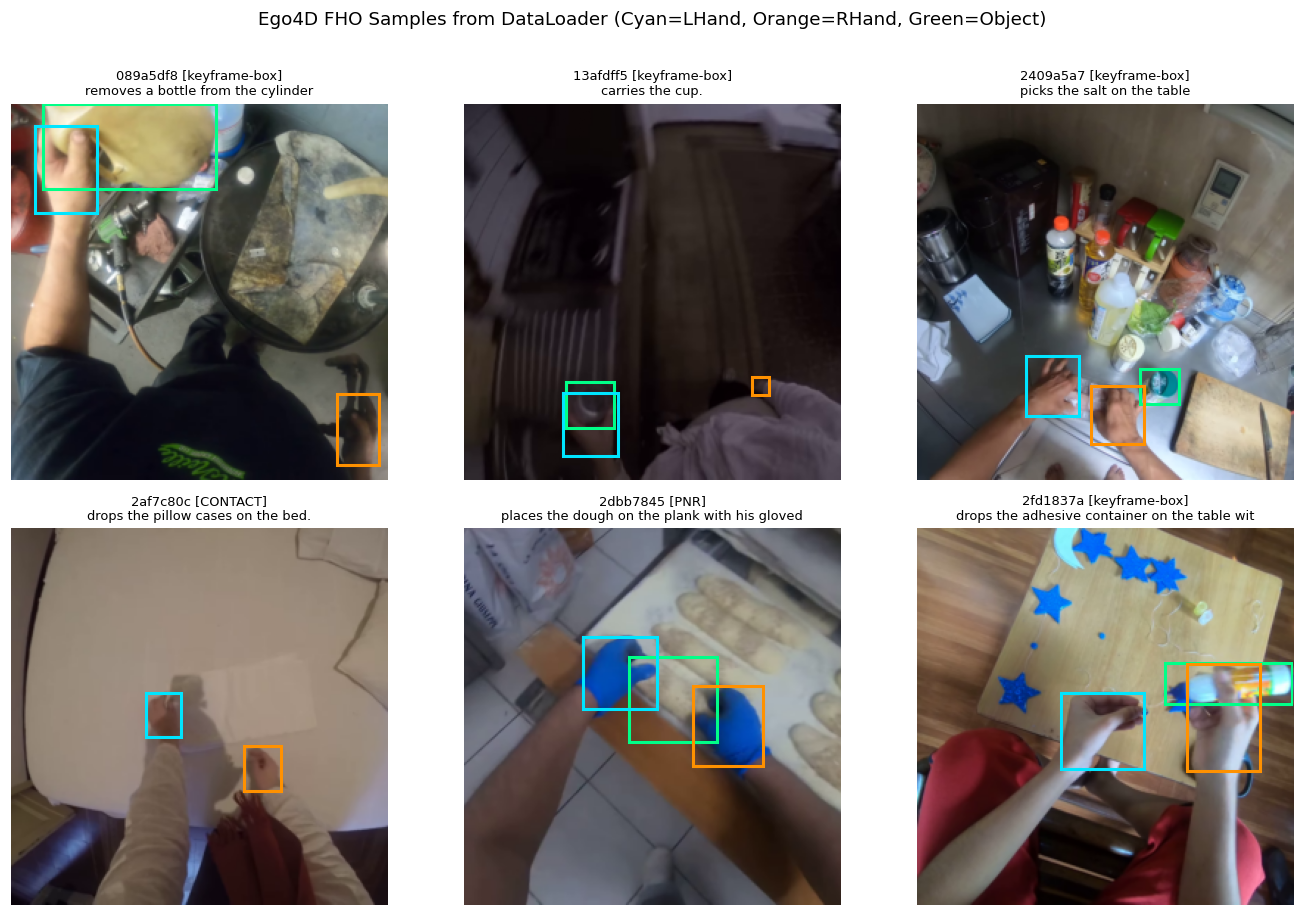

In [5]:
cfg_pass4 = {
    "clip_len": 8,
    "fps": 15,
    "max_objects": 6,
    "modalities": ["rgb", "audio", "keyframes"],
    "audio": {"sample_rate": 16000, "mono": True},
    "transforms": {"resize": 256, "center_crop": [256, 256]},
    "sources": [
        {
            "dataset": "ego4d",
            "require_modalities": ["hand_box"],
            "sampling": "actions",
        }
    ],
}

t0 = time.time()
dl_p4, _ = make_loader(cfg_pass4, PASS4_MAX_CLIPS, BATCH_SIZE_DENSE, seed=SEED + 5)

rgb_sum = np.zeros(3, np.float64)
rgb_sq = np.zeros(3, np.float64)
rgb_n = 0
fdiff_list = []
audio_rms_db = []
audio_valid_cnt = 0
vis_samples = []

for batch in dl_p4:
    frames = batch["frames"].numpy()         # (B, T, 3, H, W)
    audio = batch["audio"].numpy()           # (B, 1, S)
    a_val = batch["audio_valid"].numpy()
    hb = batch["hand_bbox_2d"].numpy()       # (B, 2, T, 4)
    hbv = batch["hand_bbox_valid"].numpy()   # (B, 2, T)
    ob = batch["obj_bbox_2d"].numpy()        # (B, O, T, 4)
    ov = batch["obj_valid"].numpy()          # (B, O, T)
    kf = batch["keyframe"].numpy()           # (B, 2, T)

    B, T = frames.shape[:2]
    rgb_sum += frames.sum(axis=(0, 1, 3, 4))
    rgb_sq += (frames ** 2).sum(axis=(0, 1, 3, 4))
    rgb_n += B * T * frames.shape[3] * frames.shape[4]
    fdiff_list.extend(np.abs(np.diff(frames, axis=1)).mean(axis=(1, 2, 3, 4)).tolist())

    for b in range(B):
        if a_val[b]:
            audio_valid_cnt += 1
            wav = audio[b, 0]
            rms = float(np.sqrt(np.mean(wav ** 2) + 1e-12))
            audio_rms_db.append(20.0 * np.log10(rms))

        # Pick frames that have at least one hand or object box for visualization
        box_frames = np.flatnonzero(hbv[b].any(axis=0) | ov[b].any(axis=0))
        if len(vis_samples) < 6 and len(box_frames) > 0:
            t = int(box_frames[0])
            tags = []
            if kf[b, 0, t]:
                tags.append("CONTACT")
            if kf[b, 1, t]:
                tags.append("PNR")
            vis_samples.append({
                "seq_id": batch["sequence_id"][b][:8],
                "action": (batch["action"][b] or "")[:45],
                "rgb": np.transpose(frames[b, t], (1, 2, 0)),
                "hb": hb[b, :, t],
                "hbv": hbv[b, :, t],
                "ob": ob[b, :, t],
                "ov": ov[b, :, t],
                "tag": "+".join(tags) if tags else "keyframe-box",
            })

rgb_mean = rgb_sum / rgb_n
rgb_std = np.sqrt(np.maximum(rgb_sq / rgb_n - rgb_mean ** 2, 0.0))

dense_df = pd.DataFrame([
    ("Pass 4 runtime / clips", f"{time.time() - t0:.1f}s / {len(dl_p4.dataset)} clips"),
    ("RGB channel mean (R, G, B)", f"({rgb_mean[0]:.3f}, {rgb_mean[1]:.3f}, {rgb_mean[2]:.3f})"),
    ("RGB channel std (R, G, B)", f"({rgb_std[0]:.3f}, {rgb_std[1]:.3f}, {rgb_std[2]:.3f})"),
    ("Mean temporal frame diff |I_t - I_{t-1}|", f"{np.mean(fdiff_list):.4f}"),
    ("Audio valid rate (FHO subset)", f"{audio_valid_cnt}/{len(dl_p4.dataset)} ({100*audio_valid_cnt/len(dl_p4.dataset):.1f}%)"),
    ("Audio RMS loudness [p10 / med / p90]", f"{np.percentile(audio_rms_db, 10):.1f} / {np.median(audio_rms_db):.1f} / {np.percentile(audio_rms_db, 90):.1f} dBFS" if audio_rms_db else "N/A"),
], columns=["Dense Ego4D Metric (Pass 4)", "Value"])
display(dense_df)

if vis_samples:
    cols = 3
    rows = int(np.ceil(len(vis_samples) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12.5, 4.1 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, s in zip(axes, vis_samples):
        ax.imshow(s["rgb"])
        for o in np.flatnonzero(s["ov"]):
            x0, y0, x1, y1 = s["ob"][o]
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="#00ff88", lw=2.0, label="Obj"))
        for side_i, col in ((0, "#00e5ff"), (1, "#ff9100")):
            if s["hbv"][side_i]:
                x0, y0, x1, y1 = s["hb"][side_i]
                ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=col, lw=2.0))
        ax.set_title(f"{s['seq_id']} [{s['tag']}]\n{s['action']}", fontsize=8.5)
        ax.axis("off")
    for ax in axes[len(vis_samples):]:
        ax.axis("off")
    plt.suptitle("Ego4D FHO Samples from DataLoader (Cyan=LHand, Orange=RHand, Green=Object)", y=1.01)
    plt.tight_layout()
    plt.show()